The data:

Alloriginaldata_19911.csv - full pool of 19,911 drugs with DILI labels

DILI_Goldstandard_1111.csv — 1,111 high-quality reference drugs (used as exclusion list)

test_data_ncv_DILIst_888.csv — 888 gold-standard drugs used as extra training data

test_data_heldouttest_DILIst_223.csv — 222 drugs locked away, never touched until final test

Build training data — take Alloriginaldata_19911.csv, remove the 222 test drugs and the 1,111 gold standard drugs → ~12,900 clean training drugs

Train RF and XGB — convert each drug to a 2048-number fingerprint, train on the 12,900 drugs. Also train a second version adding the 888 drugs from test_data_ncv_DILIst_888.csv

Pretrain graph models — train Graphormer and GraphGPS on Alloriginaldata_19911.csv minus only the 222 test drugs (~13,609 drugs) so they learn from as much data as possible first

Fine-tune graph models — take the pretrained graph models and retrain them on just the clean 12,900 drugs

Test all models — evaluate every model on test_data_heldouttest_DILIst_223.csv (222 drugs), report AUC, sensitivity, specificity

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import copy

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs
RDLogger.DisableLog('rdApp.*')

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, matthews_corrcoef, confusion_matrix,
                              roc_curve, average_precision_score, f1_score)
from xgboost import XGBClassifier

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GINConv, GATConv, TransformerConv, GINEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import get_laplacian, to_dense_adj, degree as pyg_degree

SEED    = 42
BASE    = '/Users/yaminichitikela/Desktop/qsar casepase'
DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
HIDDEN  = 256
N_LAYERS = 4
PE_DIM  = 8
BOND_DIM = 6

np.random.seed(SEED); torch.manual_seed(SEED)
print(f'Device: {DEVICE}')

Device: cpu


---
## Step 1 — Load Datasets & Leakage Check

- **Held-out-223** (`test_data_heldouttest_DILIst_223.csv`): final test set, **never** used during training or HP selection. Its SMILES are removed from the proxy set.
- **Proxy** (`proxy-DILI_dataset_12133.csv`): hepatotoxicity labels from LivTox / Mulliner et al. 2016. Held-out-223 overlaps removed. Used for **Stage 1 pretraining** for GTs and proxy-only RF/XGB.
- **NCV-888** (`test_data_ncv_DILIst_888.csv`): 888 gold-standard clinical DILI compounds. 80/20 split → `ncv_train` / `ncv_val`. Used for **Stage 2 fine-tuning** (GTs) and RF/XGB HP selection. Has 0 overlap with proxy.

In [2]:
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except:
        return None

# ── Gold-1111 exclusion set ────────────────────────────────────────────────────
gold_df = pd.read_csv(f'{BASE}/liver/DILI_Goldstandard_1111.csv')
gold_df['csmi'] = gold_df['smiles_r'].apply(canonicalize)
gold_smiles = set(gold_df['csmi'].dropna())
print(f'Gold Standard 1111: {len(gold_smiles):,} compounds')

# ── Held-out-223 (final test — NEVER used during training) ───────────────────
held_df = pd.read_csv(f'{BASE}/liver/test_data_heldouttest_DILIst_223.csv',
                      usecols=['smiles_r', 'TOXICITY'])
held_df['csmi'] = held_df['smiles_r'].apply(canonicalize)
held_df = (held_df.dropna(subset=['csmi'])
                  .drop_duplicates('csmi')
                  .reset_index(drop=True)
                  [['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'}))
held_smiles = set(held_df['csmi'])
print(f'Held-223  : {len(held_df):,}  DILI+={held_df.label.sum():,}  '
      f'DILI-={(held_df.label==0).sum():,}')

# ── Alloriginaldata: two subsets ───────────────────────────────────────────────
all_raw = pd.read_csv(f'{BASE}/liver/Alloriginaldata_19911.csv',
                      usecols=['smiles_r', 'TOXICITY'])
all_raw['csmi'] = all_raw['smiles_r'].apply(canonicalize)
all_raw = (all_raw.dropna(subset=['csmi'])
                  .drop_duplicates('csmi')
                  .reset_index(drop=True))

# Clinical training set: Alloriginaldata − Gold-1111  (paper definition: 12,900)
clin_df = (all_raw[~all_raw['csmi'].isin(gold_smiles)]
           .reset_index(drop=True)
           [['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'}))
print(f'\nClinical (Alloriginal − Gold-1111) : {len(clin_df):,}  '
      f'DILI+={clin_df.label.sum():,}  DILI-={(clin_df.label==0).sum():,}')

# GT pretraining set: Alloriginaldata − held-out-223  (~13,609, includes NCV-888)
pretrain_df = (all_raw[~all_raw['csmi'].isin(held_smiles)]
               .reset_index(drop=True)
               [['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'}))
print(f'GT pretrain (Alloriginal − held-223) : {len(pretrain_df):,}  '
      f'DILI+={pretrain_df.label.sum():,}  DILI-={(pretrain_df.label==0).sum():,}')

# ── NCV-888 (augmentation — subset of Gold Standard) ─────────────────────────
ncv_df = pd.read_csv(f'{BASE}/liver/test_data_ncv_DILIst_888.csv',
                     usecols=['smiles_r', 'TOXICITY'])
ncv_df['csmi'] = ncv_df['smiles_r'].apply(canonicalize)
ncv_df = (ncv_df.dropna(subset=['csmi'])
                .drop_duplicates('csmi')
                .reset_index(drop=True)
                [['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'}))
print(f'\nNCV-888   : {len(ncv_df):,}  DILI+={ncv_df.label.sum():,}  '
      f'DILI-={(ncv_df.label==0).sum():,}')

# Leakage checks
print(f'\nNCV-888 ∩ clinical (expected 0) : {ncv_df["csmi"].isin(set(clin_df["csmi"])).sum():,}')
print(f'NCV-888 ∩ held-223  (expected 0) : {ncv_df["csmi"].isin(held_smiles).sum():,}')

Gold Standard 1111: 1,096 compounds
Held-223  : 222  DILI+=155  DILI-=67

Clinical (Alloriginal − Gold-1111) : 12,900  DILI+=4,217  DILI-=8,683
GT pretrain (Alloriginal − held-223) : 13,609  DILI+=4,650  DILI-=8,959

NCV-888   : 874  DILI+=553  DILI-=321

NCV-888 ∩ clinical (expected 0) : 0
NCV-888 ∩ held-223  (expected 0) : 0


---
## Step 2 — Feature Engineering: ECFP4 + Molecular Graphs

All models share the same 2048-bit ECFP4 fingerprints for RF/XGB.  
GNNs and Graph Transformers use molecular graphs with **23-dim atom features** and **6-dim bond features** (`edge_attr`).  
Graphormer uses `edge_attr` directly; GraphGPS additionally appends an 8-dim Laplacian positional encoding.  
No architecture-specific graph format is needed — `mol_to_graph` produces one unified graph per molecule.

In [3]:
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

ATOM_SYMBOLS = [6, 7, 8, 16, 9, 15, 17, 35, 53]

def one_hot(val, choices):
    v = [0] * len(choices)
    try:
        v[choices.index(val)] = 1
    except ValueError:
        pass
    return v

def atom_features(atom):
    return (one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [1]
            + one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5])
            + [atom.GetFormalCharge()]
            + one_hot(int(atom.GetHybridization()), [2, 3, 4, 5])
            + [int(atom.GetIsAromatic()), int(atom.IsInRing())])

def bond_features(bond):
    bt = bond.GetBondTypeAsDouble()
    return [bt == 1.0, bt == 1.5, bt == 2.0, bt == 3.0,
            int(bond.GetIsConjugated()), int(bond.IsInRing())]

def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float)
    if mol.GetNumBonds() == 0:
        edge_index = torch.zeros((2, 0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    else:
        edges, attrs = [], []
        for b in mol.GetBonds():
            i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
            bf = bond_features(b)
            edges += [[i, j], [j, i]]
            attrs += [bf, bf]
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(attrs, dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor([label], dtype=torch.float))

ATOM_DIM = len(atom_features(Chem.MolFromSmiles('C').GetAtomWithIdx(0)))
print(f'Atom feature dim : {ATOM_DIM}')
print(f'Bond feature dim : {BOND_DIM}')

def build_features(df, name):
    fps = df['csmi'].apply(smiles_to_ecfp4)
    ok  = fps.notna().values
    df  = df[ok].reset_index(drop=True)
    X   = np.vstack(fps[ok].values)
    y   = df['label'].values.astype(int)
    graphs_raw = [mol_to_graph(smi, int(lbl)) for smi, lbl in zip(df['csmi'], y)]
    g_ok   = np.array([g is not None for g in graphs_raw])
    graphs = [g for g, v in zip(graphs_raw, g_ok) if v]
    X = X[g_ok]; y = y[g_ok]; df = df[g_ok].reset_index(drop=True)
    print(f'{name}: {len(df):,}  DILI+={int(y.sum()):,}  DILI-={int((y==0).sum()):,}')
    return df, X, y, graphs

Atom feature dim : 23
Bond feature dim : 6


In [4]:
print('Building ECFP4 + graph features for all datasets...')
clin_df,     X_clin,     y_clin,     clin_graphs     = build_features(clin_df,     'Clinical (Alloriginal − Gold-1111)')
pretrain_df, X_pretrain, y_pretrain, pretrain_graphs = build_features(pretrain_df, 'GT pretrain (Alloriginal − held-223)')
ncv_df,      X_ncv,      y_ncv,      ncv_graphs      = build_features(ncv_df,      'NCV-888 (augmentation)')
held_df,     X_held,     y_held,     held_graphs     = build_features(held_df,     'Held-out-223 (test)')

held_loader = DataLoader(held_graphs, batch_size=64)
print('\nAll features ready.')

Building ECFP4 + graph features for all datasets...
Clinical (Alloriginal − Gold-1111): 12,900  DILI+=4,217  DILI-=8,683
GT pretrain (Alloriginal − held-223): 13,609  DILI+=4,650  DILI-=8,959
NCV-888 (augmentation): 874  DILI+=553  DILI-=321
Held-out-223 (test): 222  DILI+=155  DILI-=67

All features ready.


---
## Step 3 — Train / Validation Splits

| Split | Data | N | Purpose |
|-------|------|---|---------|
| `clin_train` (80 %) | Clinical (Alloriginal − Gold-1111) | ~10,320 | GT Stage 2 fine-tune; RF/XGB training |
| `clin_val`   (10 %) | Clinical | ~1,290 | GT early stopping; RF/XGB **HP selection** |
| `pretrain_tr` (90 %) | Alloriginal − held-out-223 | ~12,248 | GT Stage 1 pretraining |
| `pretrain_va` (10 %) | Alloriginal − held-out-223 | ~1,361 | GT Stage 1 early stopping |
| `NCV-888`  (100 %) | Gold Standard augmentation | 874 | RF/XGB+NCV training |
| `held_out`   (100 %) | Held-out-223 | 223 | **Final test — never touched** |

In [5]:
# ── Clinical 80/10/10 split (RF/XGB training + GT Stage 2) ───────────────────
idx_c = np.arange(len(y_clin))
idx_c_pool, _ = train_test_split(
    idx_c, test_size=0.10, stratify=y_clin, random_state=SEED)
idx_c_tr, idx_c_va = train_test_split(
    idx_c_pool, test_size=0.10 / 0.90, stratify=y_clin[idx_c_pool], random_state=SEED)

X_c_tr, y_c_tr = X_clin[idx_c_tr], y_clin[idx_c_tr]
X_c_va, y_c_va = X_clin[idx_c_va], y_clin[idx_c_va]
g_c_tr = [clin_graphs[i] for i in idx_c_tr]
g_c_va = [clin_graphs[i] for i in idx_c_va]

clin_tr_ld = DataLoader(g_c_tr, batch_size=64, shuffle=True)
clin_va_ld = DataLoader(g_c_va, batch_size=64)
print(f'Clinical  train / val : {len(idx_c_tr):,} / {len(idx_c_va):,}')
#use the same clinical RF CGB for GT change here 

# ── GT Stage 1 pretrain split 90/10 ──────────────────────────────────────────
idx_p = np.arange(len(y_pretrain))
idx_p_tr, idx_p_va = train_test_split(
    idx_p, test_size=0.10, stratify=y_pretrain, random_state=SEED)

g_p_tr = [pretrain_graphs[i] for i in idx_p_tr]
g_p_va = [pretrain_graphs[i] for i in idx_p_va]

pretrain_tr_ld = DataLoader(g_p_tr, batch_size=128, shuffle=True)
pretrain_va_ld = DataLoader(g_p_va, batch_size=128)
print(f'Pretrain  train / val : {len(idx_p_tr):,} / {len(idx_p_va):,}')

print(f'NCV-888   (aug)       : {len(y_ncv):,}')
print(f'Held-out  test        : {len(y_held):,}')

Clinical  train / val : 10,320 / 1,290
Pretrain  train / val : 12,248 / 1,361
NCV-888   (aug)       : 874
Held-out  test        : 222


---
## Step 4 — Evaluation Helper & Shared Training Utilities

In [6]:
METRIC_COLS = ['Model', 'Sensitivity', 'Specificity', 'CCR', 'ROC-AUC', 'PR-AUC', 'MCC', 'F1']

def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / max(tp + fn, 1) * 100
    spec = tn / max(tn + fp, 1) * 100
    return {'Model'      : name,
            'Sensitivity': sens,
            'Specificity': spec,
            'CCR'        : (sens + spec) / 2,
            'ROC-AUC'    : roc_auc_score(y_true, y_prob),
            'PR-AUC'     : average_precision_score(y_true, y_prob),
            'MCC'        : matthews_corrcoef(y_true, y_pred),
            'F1'         : f1_score(y_true, y_pred, zero_division=0)}

def get_probs(encoder, head, loader, device):
    encoder.eval(); head.eval()
    probs, labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            probs.extend(torch.sigmoid(head(encoder(batch))).cpu().numpy())
            labels.extend(batch.y.cpu().numpy())
    return np.array(probs), np.array(labels)

def train_one_epoch(encoder, head, loader, optimizer, criterion, device):
    encoder.train(); head.train()
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        criterion(head(encoder(batch)), batch.y).backward()
        optimizer.step()

def run_epochs(encoder, head, train_ld, val_ld, criterion,
               max_epochs, patience, lr, device, best_state, label=''):
    """Generic training loop with early stopping; updates best_state dict in place."""
    trainable = [p for p in list(encoder.parameters()) + list(head.parameters())
                 if p.requires_grad]
    opt   = torch.optim.Adam(trainable, lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3, factor=0.5)
    no_imp = 0
    for ep in range(max_epochs):
        train_one_epoch(encoder, head, train_ld, opt, criterion, device)
        va_p, va_l = get_probs(encoder, head, val_ld, device)
        va_auc = roc_auc_score(va_l, va_p)
        sched.step(1 - va_auc)
        if va_auc > best_state['auc']:
            best_state['auc']  = va_auc
            best_state['enc']  = copy.deepcopy(encoder.state_dict())
            best_state['head'] = copy.deepcopy(head.state_dict())
            no_imp = 0
        else:
            no_imp += 1
            if no_imp >= patience:
                break
    if label:
        print(f'  [{label}] best_dili_val_AUC = {best_state["auc"]:.4f}')
    return best_state

print('Evaluation helper and training utilities ready.')

Evaluation helper and training utilities ready.


---
## Step 5 — RF & XGB: Direct Training on Clinical Data

RF and XGB train on ECFP4 fingerprints. HP selection uses `clin_val` (~1,290 in-domain compounds) in both conditions.

| Condition | Training rows | Validation for HP |
|-----------|--------------|-------------------|
| clinical-only | ~10,320 `clin_train` | `clin_val` (~1,290) |
| clinical + NCV | ~10,320 clin + 874 NCV-888 | `clin_val` (~1,290) |

In [7]:
rf_grid  = list(ParameterGrid({'n_estimators'    : [300, 500],
                                'max_features'    : ['sqrt', 0.3],
                                'min_samples_leaf': [1, 3]}))
xgb_grid = list(ParameterGrid({'n_estimators': [300, 500],
                                'max_depth'   : [4, 6],
                                'learning_rate': [0.05, 0.1]}))

def best_rf(X_tr, y_tr, X_val, y_val):
    best_auc, best_clf = 0, None
    for p in rf_grid:
        clf = RandomForestClassifier(**p, class_weight='balanced',
                                     n_jobs=-1, random_state=SEED)
        clf.fit(X_tr, y_tr)
        auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1])
        if auc > best_auc:
            best_auc, best_clf = auc, clf
    return best_clf, best_auc

def best_xgb(X_tr, y_tr, X_val, y_val):
    sw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
    best_auc, best_clf = 0, None
    for p in xgb_grid:
        clf = XGBClassifier(**p, scale_pos_weight=sw, eval_metric='logloss',
                             n_jobs=-1, random_state=SEED, verbosity=0)
        clf.fit(X_tr, y_tr)
        auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1])
        if auc > best_auc:
            best_auc, best_clf = auc, clf
    return best_clf, best_auc

# ── Clinical-only (HP selected on clin_val ~1,290) ───────────────────────────
print('--- RF / XGB  clinical-only ---')
rf_clin,  auc_v = best_rf( X_c_tr, y_c_tr, X_c_va, y_c_va)
print(f'  RF  clin_val AUC = {auc_v:.4f}')
xgb_clin, auc_v = best_xgb(X_c_tr, y_c_tr, X_c_va, y_c_va)
print(f'  XGB clin_val AUC = {auc_v:.4f}')

# ── Clinical + NCV-888 (HP selected on clin_val) ─────────────────────────────
X_aug = np.vstack([X_c_tr, X_ncv])
y_aug = np.concatenate([y_c_tr, y_ncv])
print(f'\n--- RF / XGB  clinical+NCV  ({len(X_aug):,} rows) ---')
rf_aug,  auc_v = best_rf( X_aug, y_aug, X_c_va, y_c_va)
print(f'  RF  clin_val AUC = {auc_v:.4f}')
xgb_aug, auc_v = best_xgb(X_aug, y_aug, X_c_va, y_c_va)
print(f'  XGB clin_val AUC = {auc_v:.4f}')
#add internal test set evaluation as well 

# ── Evaluate on held-out 223 ──────────────────────────────────────────────────
p_rf_clin  = rf_clin.predict_proba(X_held)[:, 1]
p_xgb_clin = xgb_clin.predict_proba(X_held)[:, 1]
p_rf_aug   = rf_aug.predict_proba(X_held)[:, 1]
p_xgb_aug  = xgb_aug.predict_proba(X_held)[:, 1]

print('\n=== RF / XGB on Held-out 223 ===')
print(f'{"Model":<35}  {"Sens":>5}  {"Spec":>5}  {"CCR":>5}  {"AUC":>6}  {"PR-AUC":>6}  {"MCC":>6}  {"F1":>5}')
print('-' * 84)
for name, prob in [('RF  (clinical-only)',  p_rf_clin),
                   ('RF  (clinical+NCV)',   p_rf_aug),
                   ('XGB (clinical-only)',  p_xgb_clin),
                   ('XGB (clinical+NCV)',   p_xgb_aug)]:
    r = evaluate(y_held, prob, name)
    print(f'{r["Model"]:<35}  {r["Sensitivity"]:>4.1f}%  {r["Specificity"]:>4.1f}%  '
          f'{r["CCR"]:>4.1f}%  {r["ROC-AUC"]:>6.4f}  {r["PR-AUC"]:>6.4f}  '
          f'{r["MCC"]:>6.4f}  {r["F1"]:>5.4f}')

--- RF / XGB  clinical-only ---
  RF  clin_val AUC = 0.7436
  XGB clin_val AUC = 0.7447

--- RF / XGB  clinical+NCV  (11,194 rows) ---
  RF  clin_val AUC = 0.7451
  XGB clin_val AUC = 0.7438

=== RF / XGB on Held-out 223 ===
Model                                 Sens   Spec    CCR     AUC  PR-AUC     MCC     F1
------------------------------------------------------------------------------------
RF  (clinical-only)                  52.3%  77.6%  64.9%  0.6711  0.8138  0.2768  0.6454
RF  (clinical+NCV)                   53.5%  74.6%  64.1%  0.6855  0.8222  0.2600  0.6510
XGB (clinical-only)                  65.2%  61.2%  63.2%  0.6580  0.8057  0.2445  0.7163
XGB (clinical+NCV)                   65.8%  64.2%  65.0%  0.6738  0.8278  0.2778  0.7260


---
## Step 6 — Graphormer & GraphGPS: Two-Stage Training on Clinical Data

GT models follow the **same data protocol as RF/XGB** — no large proxy pretraining.

| Stage | Training rows | Validation |
|-------|--------------|------------|
| Stage 1 — clinical-only | ~10,320 `clin_train` | `clin_val` (~1,290) |
| Stage 2 — clinical + NCV | ~10,320 clin + 874 NCV-888 | `clin_val` (~1,290) |

- **Stage 1**: Train GT from scratch on `clin_train` (same data as RF/XGB clinical-only)
- **Stage 2**: Fine-tune Stage 1 weights on `clin_train + NCV-888` (same data as RF/XGB +NCV)

HP selection and early stopping both use `clin_val` (~1,290) — identical to RF/XGB.

In [8]:
# ── Classification head (shared by both GT models) ───────────────────────────
class ClassHead(nn.Module):
    def __init__(self, hidden=256, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden, hidden // 2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden // 2, 1))

    def forward(self, h):
        return self.net(h).squeeze(-1)

# ── Laplacian PE for GraphGPS ─────────────────────────────────────────────────
def compute_laplacian_pe(data, k=PE_DIM):
    n = data.num_nodes
    if n <= 2:
        return torch.zeros(n, k)
    ei, ew = get_laplacian(data.edge_index, normalization='sym', num_nodes=n)
    L = to_dense_adj(ei, edge_attr=ew, max_num_nodes=n).squeeze(0).numpy()
    try:
        import numpy.linalg as nla
        _, vecs = nla.eigh(L)
        num_take = min(k, n - 1)
        pe = torch.from_numpy(vecs[:, 1:1 + num_take]).float()
        if pe.shape[1] < k:
            pe = F.pad(pe, (0, k - pe.shape[1]))
    except Exception:
        pe = torch.zeros(n, k)
    return pe

def add_pe(graph_list, k=PE_DIM):
    out = []
    for d in graph_list:
        pe = compute_laplacian_pe(d, k)
        out.append(Data(x=d.x, edge_index=d.edge_index,
                        edge_attr=d.edge_attr, y=d.y, pe=pe))
    return out

# ── Graphormer encoder ────────────────────────────────────────────────────────
class GraphormerEncoder(nn.Module):
    def __init__(self, in_dim, hidden=256, n_heads=4, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden = hidden; self.dropout = dropout
        assert hidden % n_heads == 0
        head_dim = hidden // n_heads
        self.input_proj = nn.Linear(in_dim, hidden)
        self.degree_emb = nn.Embedding(100, hidden)
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            self.convs.append(TransformerConv(hidden, head_dim, heads=n_heads,
                                              edge_dim=BOND_DIM, concat=True,
                                              dropout=dropout, beta=True))
            self.bns.append(nn.LayerNorm(hidden))

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        h   = self.input_proj(x)
        deg = pyg_degree(ei[0], num_nodes=x.size(0)).long().clamp(max=99)
        h   = F.relu(h + self.degree_emb(deg))
        for conv, bn in zip(self.convs, self.bns):
            h = bn(F.gelu(conv(h, ei, ea)))
            h = F.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, batch)

# ── GraphGPS encoder ──────────────────────────────────────────────────────────
class GraphGPSEncoder(nn.Module):
    def __init__(self, in_dim, hidden=256, pe_dim=PE_DIM,
                 n_heads=4, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden = hidden; self.dropout = dropout
        assert hidden % n_heads == 0
        self.input_proj = nn.Linear(in_dim + pe_dim, hidden)
        self.convs = nn.ModuleList()
        self.attn  = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(),
                                nn.Linear(hidden, hidden))
            self.convs.append(GINEConv(mlp, edge_dim=BOND_DIM))
            self.attn.append(nn.MultiheadAttention(
                hidden, n_heads, dropout=dropout, batch_first=True))
            self.bns.append(nn.LayerNorm(hidden))

    def forward(self, data):
        from torch_geometric.utils import to_dense_batch
        x, ei, ea, batch, pe = (
            data.x, data.edge_index, data.edge_attr, data.batch, data.pe)
        h = self.input_proj(torch.cat([x, pe], dim=-1))
        for conv, attn, bn in zip(self.convs, self.attn, self.bns):
            h_local = conv(h, ei, ea)
            h_dense, mask = to_dense_batch(h, batch)
            h_global, _   = attn(h_dense, h_dense, h_dense, key_padding_mask=~mask)
            h_global = h_global[mask]
            h = bn(h + h_local + h_global)
            h = F.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, batch)

# ── Generic training loop for GT models ──────────────────────────────────────
def train_gt_model(encoder, head, train_ld, val_ld, criterion,
                   max_epochs=80, patience=15, lr=1e-3, label=''):
    opt   = torch.optim.Adam(
        list(encoder.parameters()) + list(head.parameters()), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=5, factor=0.5)
    best  = {'auc': 0.0, 'enc': None, 'head': None}
    no_imp = 0
    for ep in range(max_epochs):
        train_one_epoch(encoder, head, train_ld, opt, criterion, DEVICE)
        va_p, va_l = get_probs(encoder, head, val_ld, DEVICE)
        va_auc = roc_auc_score(va_l, va_p)
        sched.step(1 - va_auc)
        if va_auc > best['auc']:
            best['auc']  = va_auc
            best['enc']  = copy.deepcopy(encoder.state_dict())
            best['head'] = copy.deepcopy(head.state_dict())
            no_imp = 0
        else:
            no_imp += 1
            if no_imp >= patience:
                if label:
                    print(f'  [{label}] early stop ep {ep+1}  '
                          f'best = {best["auc"]:.4f}')
                break
        if label and (ep + 1) % 20 == 0:
            print(f'  [{label}] ep {ep+1:3d}  val = {va_auc:.4f}  '
                  f'best = {best["auc"]:.4f}')
    encoder.load_state_dict(best['enc'])
    head.load_state_dict(best['head'])
    return best['auc']

print('ClassHead, Graphormer / GraphGPS encoders + train_gt_model defined.')

ClassHead, Graphormer / GraphGPS encoders + train_gt_model defined.


In [9]:
# Add Laplacian PE (needed only by GraphGPS)
print('Computing Laplacian PE for GraphGPS graph sets...')
gps_c_tr   = add_pe(g_c_tr)
gps_c_va   = add_pe(g_c_va)
gps_ncv    = add_pe(ncv_graphs)
gps_held   = add_pe(held_graphs)

gps_clin_tr_ld = DataLoader(gps_c_tr, batch_size=64, shuffle=True)
gps_clin_va_ld = DataLoader(gps_c_va, batch_size=64)
gps_ncv_ld     = DataLoader(gps_ncv,  batch_size=64)
gps_held_ld    = DataLoader(gps_held, batch_size=64)

print(f'GPS clinical train/val : {len(gps_c_tr):,} / {len(gps_c_va):,}')
print(f'GPS NCV-888            : {len(gps_ncv):,}')
print(f'GPS held-out-223       : {len(gps_held):,}')

# ── Augmented loaders: Clinical train + NCV-888 (GT Stage 2) ─────────────────
g_aug_tr      = g_c_tr + ncv_graphs
aug_tr_ld     = DataLoader(g_aug_tr, batch_size=64, shuffle=True)

gps_aug_tr    = gps_c_tr + gps_ncv
gps_aug_tr_ld = DataLoader(gps_aug_tr, batch_size=64, shuffle=True)

y_aug_gt  = np.concatenate([y_c_tr, y_ncv])
pos_w_aug = torch.tensor(
    [(y_aug_gt == 0).sum() / max((y_aug_gt == 1).sum(), 1)],
    dtype=torch.float).to(DEVICE)
crit_aug = nn.BCEWithLogitsLoss(pos_weight=pos_w_aug)
print(f'\nGT aug (Clinical + NCV-888) train : {len(g_aug_tr):,}')

Computing Laplacian PE for GraphGPS graph sets...
GPS clinical train/val : 10,320 / 1,290
GPS NCV-888            : 874
GPS held-out-223       : 222

GT aug (Clinical + NCV-888) train : 11,194


In [10]:
pos_w_clin = torch.tensor(
    [(y_c_tr == 0).sum() / max((y_c_tr == 1).sum(), 1)],
    dtype=torch.float).to(DEVICE)
crit_clin = nn.BCEWithLogitsLoss(pos_weight=pos_w_clin)

# ── Graphormer Stage 1: Train on Clinical (~10,320) ───────────────────────────
grph_enc  = GraphormerEncoder(ATOM_DIM, hidden=HIDDEN,
                               n_heads=4, n_layers=N_LAYERS).to(DEVICE)
grph_head = ClassHead(hidden=HIDDEN).to(DEVICE)

print('=== Graphormer Stage 1 — Train on Clinical (~10,320) ===')
train_gt_model(grph_enc, grph_head,
               clin_tr_ld, clin_va_ld, crit_clin,
               max_epochs=80, patience=15, lr=1e-3, label='Graphormer-Stage1')
grph_stage1_enc_w  = copy.deepcopy(grph_enc.state_dict())
grph_stage1_head_w = copy.deepcopy(grph_head.state_dict())

p_grph_clin, _ = get_probs(grph_enc, grph_head, held_loader, DEVICE)
r = evaluate(y_held, p_grph_clin, 'Graphormer Stage-1 (Clinical)')
print(f'  AUC={r["ROC-AUC"]:.4f}  Sens={r["Sensitivity"]:.1f}%  Spec={r["Specificity"]:.1f}%')

# ── Graphormer Stage 2: Fine-tune on Clinical + NCV-888 (~11,194) ─────────────
grph_enc2  = GraphormerEncoder(ATOM_DIM, hidden=HIDDEN,
                                n_heads=4, n_layers=N_LAYERS).to(DEVICE)
grph_head2 = ClassHead(hidden=HIDDEN).to(DEVICE)
grph_enc2.load_state_dict(grph_stage1_enc_w)
grph_head2.load_state_dict(grph_stage1_head_w)

print('\n=== Graphormer Stage 2 — Fine-tune on Clinical + NCV-888 (~11,194) ===')
train_gt_model(grph_enc2, grph_head2,
               aug_tr_ld, clin_va_ld, crit_aug,
               max_epochs=60, patience=12, lr=5e-4, label='Graphormer-Stage2')

p_grph_aug, _ = get_probs(grph_enc2, grph_head2, held_loader, DEVICE)
r = evaluate(y_held, p_grph_aug, 'Graphormer Stage-2 (Clinical+NCV)')
print(f'  AUC={r["ROC-AUC"]:.4f}  Sens={r["Sensitivity"]:.1f}%  Spec={r["Specificity"]:.1f}%')

=== Graphormer Stage 1 — Train on Clinical (~10,320) ===
  [Graphormer-Stage1] ep  20  val = 0.6404  best = 0.6462
  [Graphormer-Stage1] ep  40  val = 0.6516  best = 0.6521
  [Graphormer-Stage1] ep  60  val = 0.6555  best = 0.6555
  [Graphormer-Stage1] ep  80  val = 0.6581  best = 0.6585
  AUC=0.6507  Sens=74.8%  Spec=38.8%

=== Graphormer Stage 2 — Fine-tune on Clinical + NCV-888 (~11,194) ===
  [Graphormer-Stage2] ep  20  val = 0.6567  best = 0.6610
  [Graphormer-Stage2] early stop ep 21  best = 0.6610
  AUC=0.6427  Sens=85.8%  Spec=25.4%


In [11]:
# ── GraphGPS Stage 1: Train on Clinical (~10,320) ────────────────────────────
gps_enc  = GraphGPSEncoder(ATOM_DIM, hidden=HIDDEN, pe_dim=PE_DIM,
                            n_heads=4, n_layers=N_LAYERS).to(DEVICE)
gps_head = ClassHead(hidden=HIDDEN).to(DEVICE)

print('=== GraphGPS Stage 1 — Train on Clinical (~10,320) ===')
train_gt_model(gps_enc, gps_head,
               gps_clin_tr_ld, gps_clin_va_ld, crit_clin,
               max_epochs=80, patience=15, lr=1e-3, label='GraphGPS-Stage1')
gps_stage1_enc_w  = copy.deepcopy(gps_enc.state_dict())
gps_stage1_head_w = copy.deepcopy(gps_head.state_dict())

p_gps_clin, _ = get_probs(gps_enc, gps_head, gps_held_ld, DEVICE)
r = evaluate(y_held, p_gps_clin, 'GraphGPS Stage-1 (Clinical)')
print(f'  AUC={r["ROC-AUC"]:.4f}  Sens={r["Sensitivity"]:.1f}%  Spec={r["Specificity"]:.1f}%')

# ── GraphGPS Stage 2: Fine-tune on Clinical + NCV-888 (~11,194) ───────────────
gps_enc2  = GraphGPSEncoder(ATOM_DIM, hidden=HIDDEN, pe_dim=PE_DIM,
                             n_heads=4, n_layers=N_LAYERS).to(DEVICE)
gps_head2 = ClassHead(hidden=HIDDEN).to(DEVICE)
gps_enc2.load_state_dict(gps_stage1_enc_w)
gps_head2.load_state_dict(gps_stage1_head_w)

print('\n=== GraphGPS Stage 2 — Fine-tune on Clinical + NCV-888 (~11,194) ===')
train_gt_model(gps_enc2, gps_head2,
               gps_aug_tr_ld, gps_clin_va_ld, crit_aug,
               max_epochs=60, patience=12, lr=5e-4, label='GraphGPS-Stage2')

p_gps_aug, _ = get_probs(gps_enc2, gps_head2, gps_held_ld, DEVICE)
r = evaluate(y_held, p_gps_aug, 'GraphGPS Stage-2 (Clinical+NCV)')
print(f'  AUC={r["ROC-AUC"]:.4f}  Sens={r["Sensitivity"]:.1f}%  Spec={r["Specificity"]:.1f}%')

=== GraphGPS Stage 1 — Train on Clinical (~10,320) ===
  [GraphGPS-Stage1] ep  20  val = 0.6456  best = 0.6474
  [GraphGPS-Stage1] ep  40  val = 0.6626  best = 0.6676
  [GraphGPS-Stage1] ep  60  val = 0.6764  best = 0.6813
  [GraphGPS-Stage1] early stop ep 64  best = 0.6813
  AUC=0.5699  Sens=43.2%  Spec=74.6%

=== GraphGPS Stage 2 — Fine-tune on Clinical + NCV-888 (~11,194) ===
  [GraphGPS-Stage2] ep  20  val = 0.6915  best = 0.6915
  [GraphGPS-Stage2] early stop ep 34  best = 0.6939
  AUC=0.5752  Sens=57.4%  Spec=53.7%


---
## Step 7 — Full Summary Table 6 & ROC Curves

All models evaluated on the **held-out 223** test set (never seen during training or HP selection).
Results sorted by ROC-AUC descending.

In [12]:
# ── Consensus predictions ──────────────────────────────────────────────────────
p_cons_classic_clin  = np.mean([p_rf_clin,  p_xgb_clin],              axis=0)
p_cons_classic_aug   = np.mean([p_rf_aug,   p_xgb_aug],               axis=0)
p_cons_gt_clin       = np.mean([p_grph_clin, p_gps_clin],             axis=0)
p_cons_gt_aug        = np.mean([p_grph_aug,  p_gps_aug],              axis=0)
p_cons_full_clin     = np.mean([p_rf_clin,  p_xgb_clin,
                                 p_grph_clin, p_gps_clin],            axis=0)
p_cons_full_aug      = np.mean([p_rf_aug,   p_xgb_aug,
                                 p_grph_aug,  p_gps_aug],             axis=0)
p_cons_all           = np.mean([p_rf_clin,  p_rf_aug,
                                 p_xgb_clin, p_xgb_aug,
                                 p_grph_clin, p_grph_aug,
                                 p_gps_clin,  p_gps_aug],             axis=0)

model_rows = [
    ('RF          Stage-1  (Clinical)',                               p_rf_clin),
    ('RF          Stage-2  (Clinical + NCV-888)',                     p_rf_aug),
    ('XGB         Stage-1  (Clinical)',                               p_xgb_clin),
    ('XGB         Stage-2  (Clinical + NCV-888)',                     p_xgb_aug),
    ('Graphormer  Stage-1  (Clinical)',                               p_grph_clin),
    ('Graphormer  Stage-2  (Clinical + NCV-888)',                     p_grph_aug),
    ('GraphGPS    Stage-1  (Clinical)',                               p_gps_clin),
    ('GraphGPS    Stage-2  (Clinical + NCV-888)',                     p_gps_aug),
    ('Consensus Classic  Stage-1  (RF+XGB, Clinical)',                p_cons_classic_clin),
    ('Consensus GT       Stage-1  (Graphormer+GPS, Clinical)',        p_cons_gt_clin),
    ('Consensus Classic  Stage-2  (RF+XGB, Clinical+NCV)',            p_cons_classic_aug),
    ('Consensus GT       Stage-2  (Graphormer+GPS, Clinical+NCV)',    p_cons_gt_aug),
    ('Consensus Full     Stage-1  (all models, Clinical)',            p_cons_full_clin),
    ('Consensus Full     Stage-2  (all models, Clinical+NCV)',        p_cons_full_aug),
    ('Consensus All      (all models, both settings)',                p_cons_all),
]

all_results = [evaluate(y_held, prob, name) for name, prob in model_rows]
df_table6   = pd.DataFrame(all_results).reset_index(drop=True)

W = 58
print('=== Table 6 — Held-out 223 Results ===')
print(f'{"Model":<{W}}  {"Sens":>5}  {"Spec":>5}  {"CCR":>5}  {"AUC":>6}  {"PR-AUC":>6}  {"MCC":>6}  {"F1":>5}')
print('-' * (W + 54))
for _, row in df_table6.iterrows():
    print(f'{row["Model"]:<{W}}  {row["Sensitivity"]:>4.1f}%  {row["Specificity"]:>4.1f}%  '
          f'{row["CCR"]:>4.1f}%  {row["ROC-AUC"]:>6.4f}  {row["PR-AUC"]:>6.4f}  '
          f'{row["MCC"]:>6.4f}  {row["F1"]:>5.4f}')

df_table6.to_csv(f'{BASE}/liver/table6_results.csv', index=False)
print('\nResults saved → liver/table6_results.csv')

=== Table 6 — Held-out 223 Results ===
Model                                                        Sens   Spec    CCR     AUC  PR-AUC     MCC     F1
----------------------------------------------------------------------------------------------------------------
RF          Stage-1  (Clinical)                             52.3%  77.6%  64.9%  0.6711  0.8138  0.2768  0.6454
RF          Stage-2  (Clinical + NCV-888)                   53.5%  74.6%  64.1%  0.6855  0.8222  0.2600  0.6510
XGB         Stage-1  (Clinical)                             65.2%  61.2%  63.2%  0.6580  0.8057  0.2445  0.7163
XGB         Stage-2  (Clinical + NCV-888)                   65.8%  64.2%  65.0%  0.6738  0.8278  0.2778  0.7260
Graphormer  Stage-1  (Clinical)                             74.8%  38.8%  56.8%  0.6507  0.7924  0.1376  0.7436
Graphormer  Stage-2  (Clinical + NCV-888)                   85.8%  25.4%  55.6%  0.6427  0.7896  0.1349  0.7870
GraphGPS    Stage-1  (Clinical)                             43.2%

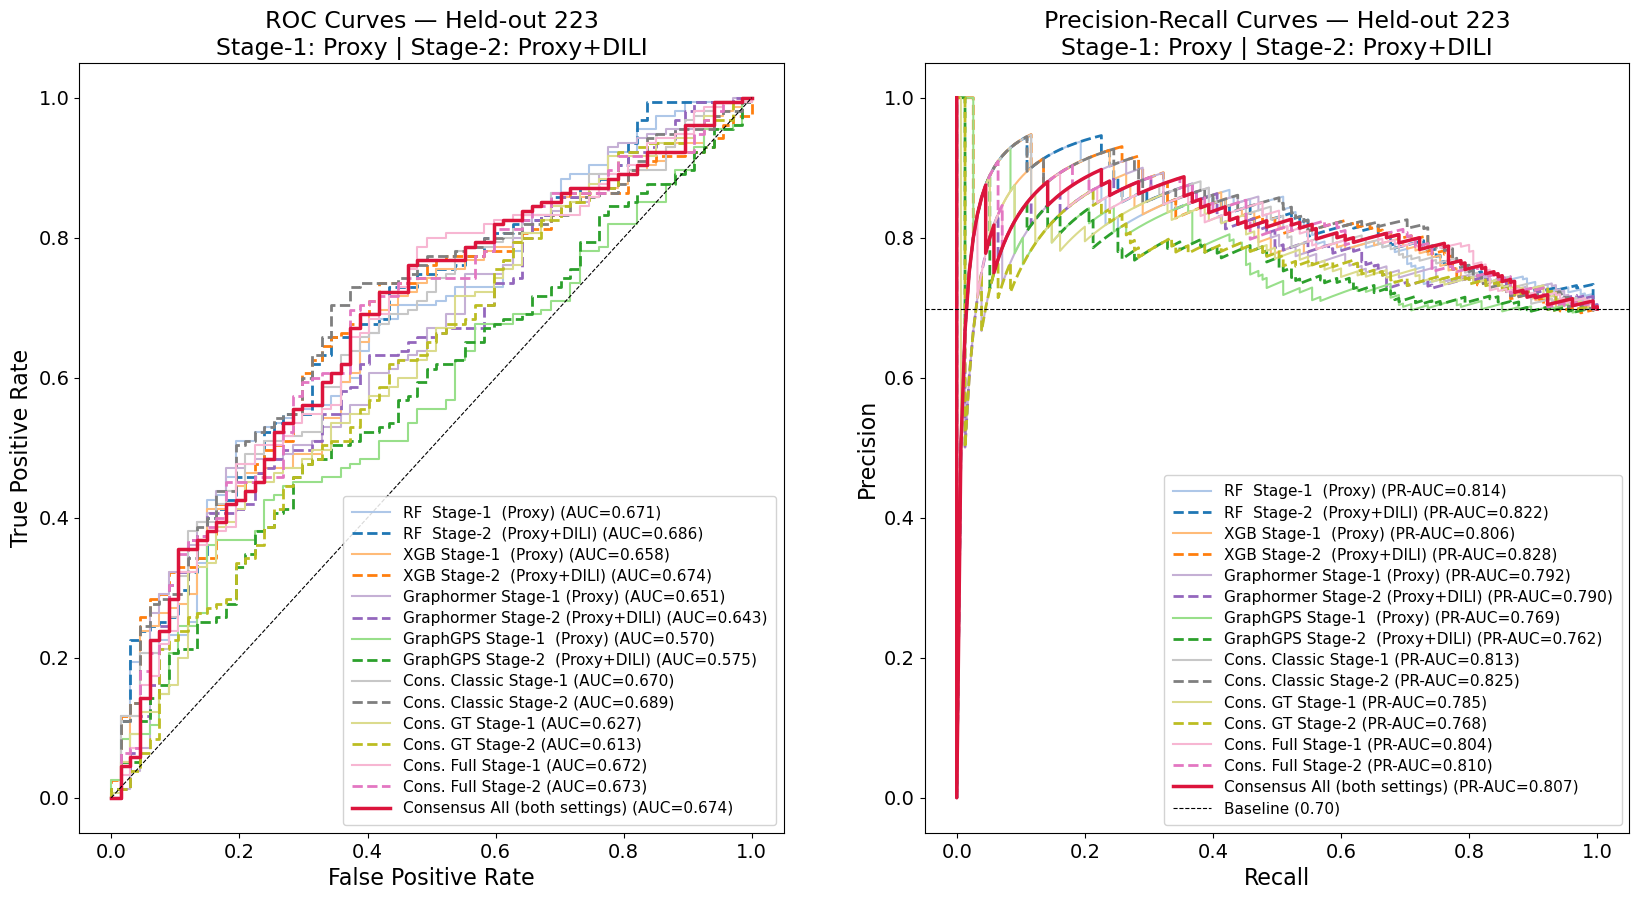

In [24]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# color / style: Stage-1 = light + solid, Stage-2 = dark + dashed
plot_specs = [
    # RF
    ('RF  Stage-1  (Proxy)',            p_rf_clin,           '#aec7e8', '-',   1.5),
    ('RF  Stage-2  (Proxy+DILI)',        p_rf_aug,            '#1f77b4', '--',  2.0),
    # XGB
    ('XGB Stage-1  (Proxy)',            p_xgb_clin,          '#ffbb78', '-',   1.5),
    ('XGB Stage-2  (Proxy+DILI)',        p_xgb_aug,           '#ff7f0e', '--',  2.0),
    # Graphormer
    ('Graphormer Stage-1 (Proxy)',      p_grph_clin,         '#c5b0d5', '-',   1.5),
    ('Graphormer Stage-2 (Proxy+DILI)', p_grph_aug,           '#9467bd', '--',  2.0),
    # GraphGPS
    ('GraphGPS Stage-1  (Proxy)',       p_gps_clin,          '#98df8a', '-',   1.5),
    ('GraphGPS Stage-2  (Proxy+DILI)',  p_gps_aug,            '#2ca02c', '--',  2.0),
    # Consensus Classic
    ('Cons. Classic Stage-1',              p_cons_classic_clin, '#c7c7c7', '-',   1.5),
    ('Cons. Classic Stage-2',              p_cons_classic_aug,  '#7f7f7f', '--',  2.0),
    # Consensus GT
    ('Cons. GT Stage-1',                   p_cons_gt_clin,      '#dbdb8d', '-',   1.5),
    ('Cons. GT Stage-2',                   p_cons_gt_aug,       '#bcbd22', '--',  2.0),
    # Consensus Full
    ('Cons. Full Stage-1',                 p_cons_full_clin,    '#f7b6d2', '-',   1.5),
    ('Cons. Full Stage-2',                 p_cons_full_aug,     '#e377c2', '--',  2.0),
    # Consensus All
    ('Consensus All (both settings)',      p_cons_all,          'crimson', '-',   2.5),
]

# ── ROC curves ────────────────────────────────────────────────────────────────
ax = axes[0]
for name, prob, color, ls, lw in plot_specs:
    fpr, tpr, _ = roc_curve(y_held, prob)
    auc = roc_auc_score(y_held, prob)
    ax.plot(fpr, tpr, color=color, ls=ls, lw=lw,
            label=f'{name} (AUC={auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_xlabel('False Positive Rate', fontsize=16)
ax.set_ylabel('True Positive Rate',  fontsize=16)
ax.set_title('ROC Curves — Held-out 223\nStage-1: Proxy | Stage-2: Proxy+DILI',
             fontsize=17)
ax.tick_params(axis='both', labelsize=14)
ax.legend(fontsize=11, loc='lower right', framealpha=0.85,
          handlelength=2.5, borderpad=0.6, labelspacing=0.4)

# ── PR curves ─────────────────────────────────────────────────────────────────
baseline = y_held.sum() / len(y_held)
ax2 = axes[1]
for name, prob, color, ls, lw in plot_specs:
    prec, rec, _ = precision_recall_curve(y_held, prob)
    pr_auc = average_precision_score(y_held, prob)
    ax2.plot(rec, prec, color=color, ls=ls, lw=lw,
             label=f'{name} (PR-AUC={pr_auc:.3f})')
ax2.axhline(baseline, color='k', ls='--', lw=0.8, label=f'Baseline ({baseline:.2f})')
ax2.set_xlabel('Recall',     fontsize=16)
ax2.set_ylabel('Precision',  fontsize=16)
ax2.set_title('Precision-Recall Curves — Held-out 223\nStage-1: Proxy | Stage-2: Proxy+DILI',
              fontsize=17)
ax2.tick_params(axis='both', labelsize=14)
ax2.legend(fontsize=11, loc='lower right', framealpha=0.85,
           handlelength=2.5, borderpad=0.6, labelspacing=0.4)

In [14]:
#read csv file all original data and see the columns
all_original_df = pd.read_csv(f'{BASE}/liver/Alloriginaldata_19911.csv')

In [15]:
#get the rows count in the df
print(f'Alloriginal data row count: {len(all_original_df)}')
all_original_df.head()

Alloriginal data row count: 19911


,smiles_r,TOXICITY,Source_rank,Source,Data
0,CCN(CC)c1cc(C)nc2ncnn12,1,1,DILIst Classification,DILI
1,CCN(CC)CC(=O)Oc1ccc(NC(C)=O)cc1,1,1,DILIst Classification,DILI
2,CCN(CC)Cc1cc(Nc2ccnc3cc(Cl)ccc23)ccc1O,1,1,DILIst Classification,DILI
3,CCN(CC)CCCC(C)Nc1ccnc2cc(Cl)ccc12,1,1,DILIst Classification Oral,DILI
4,CCN(CC)CCN1C(=O)CN=C(c2ccccc2F)c2cc(Cl)ccc21,1,1,DILIst Classification Oral,DILI


In [16]:
all_original_df['canonical_smiles'] = all_original_df['smiles_r'].apply(canonicalize)
unique_rows = len(all_original_df.dropna(subset=['canonical_smiles']).drop_duplicates(subset=['canonical_smiles']))
unique_rows

13788

In [17]:
#read csv file all original data and see the columns
all_original_df = pd.read_csv(f'{BASE}/liver/proxy-DILI_dataset_12133.csv')

In [21]:
import numpy as np

np.save('y_held.npy', y_held)
np.save('p_rf_clin.npy', p_rf_clin)
np.save('p_rf_aug.npy', p_rf_aug)
np.save('p_xgb_clin.npy', p_xgb_clin)
np.save('p_xgb_aug.npy', p_xgb_aug)
np.save('p_grph_clin.npy', p_grph_clin)
np.save('p_grph_aug.npy', p_grph_aug)
np.save('p_gps_clin.npy', p_gps_clin)
np.save('p_gps_aug.npy', p_gps_aug)

# Then print them as text
for name, arr in [
    ('y_held', y_held),
    ('p_rf_clin', p_rf_clin), ('p_rf_aug', p_rf_aug),
    ('p_xgb_clin', p_xgb_clin), ('p_xgb_aug', p_xgb_aug),
    ('p_grph_clin', p_grph_clin), ('p_grph_aug', p_grph_aug),
    ('p_gps_clin', p_gps_clin), ('p_gps_aug', p_gps_aug),
]:
    print(f'{name} = np.array({arr.tolist()})')

y_held = np.array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])
p_rf_clin = np.array([0.4836722211014174, 0.5587188017573225, 0.4407638468105722, 0.7018294817625461, 0.2606792680937962, 0.6232580273691245, 0.654223816823082, 0.5037565226590339, 0.6708611539024502, 0.6235945954615444, 0.6623852534920028, 0.5844806127119113, 0.5638744975263132, 0.5969506738681131, 0.65463205201